# Random forests

A [decision tree](decision_trees.ipynb) is unstable: a few different training rows can produce a very different tree, and an unlimited tree follows the noise of its rows. In the vocabulary of [Overfitting and the train/test split](../../ml-fundamentals/overfitting_and_the_split.ipynb), it has high **variance**.

An **ensemble** combines many models into one prediction: the average of their predictions in regression, a vote in classification. Averaging helps only where the models make *different* errors, so that they cancel out; models that make the same errors average to the same errors. A random forest is an ensemble of trees made deliberately different from one another.

## The data

The simulated salaries of [Overfitting and the train/test split](../../ml-fundamentals/overfitting_and_the_split.ipynb), with the same split, so that every model here is measured on the same 28 test employees as the line and the trees there:

In [ ]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split

rng = np.random.default_rng(seed=42)
years = rng.uniform(0, 12, size=140).round(2)
salary = 22_000 + 2_600 * years + rng.normal(0, 4_000, size=140)
salaries = pd.DataFrame({"YearsExperience": years, "Salary": salary.round(-2)})

X = salaries[["YearsExperience"]]
y = salaries["Salary"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

## Many trees on resampled data

Each tree is trained on a **bootstrap sample**: as many rows as the training set, drawn at random *with replacement*, so that some rows appear several times and others not at all. On average a bootstrap sample contains about 63% of the distinct rows ($1 - 1/e \approx 0.632$):

In [ ]:
rng = np.random.default_rng(0)
bootstrap_positions = rng.integers(0, len(X_train), size=len(X_train))
len(np.unique(bootstrap_positions)) / len(X_train)

0.6339285714285714

Training a model on each of many bootstrap samples and averaging them is called **bagging** (*bootstrap aggregating*). Trees with at least 5 rows in each leaf, each on its own bootstrap sample: five of them drawn thin, and the average of a hundred drawn thick:

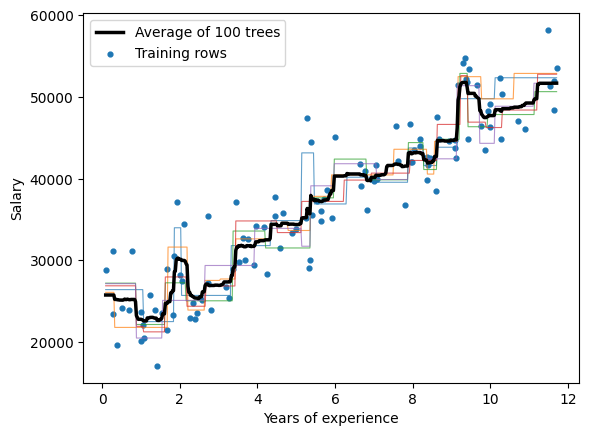

In [ ]:
import matplotlib.pyplot as plt
from sklearn.tree import DecisionTreeRegressor

grid = pd.DataFrame({"YearsExperience": np.linspace(X_train.min(), X_train.max(), num=500).ravel()})
tree_predictions = []
for seed in range(100):
    positions = np.random.default_rng(seed).integers(0, len(X_train), size=len(X_train))
    tree = DecisionTreeRegressor(min_samples_leaf=5, random_state=seed).fit(X_train.iloc[positions], y_train.iloc[positions])
    tree_predictions.append(tree.predict(grid))
    if seed < 5:
        plt.plot(grid, tree_predictions[-1], linewidth=0.8, alpha=0.7)

plt.plot(grid, np.mean(tree_predictions, axis=0), color="black", linewidth=2.5, label="Average of 100 trees")
plt.scatter(X_train, y_train, color="tab:blue", s=12, label="Training rows")
plt.xlabel("Years of experience")
plt.ylabel("Salary")
plt.legend()
plt.show()

Each thin line is one tree: a staircase that jumps to follow the rows of its own sample. The trees jump in different places, because each saw different rows, and in the average those jumps partly cancel: the thick line follows the trend with smaller, more gradual steps than any single tree.

## A random forest

A random forest adds a second source of difference between its trees: at each split, a tree may only choose among a random subset of the features (`max_features`). Otherwise, when one feature is much stronger than the rest, every tree would split on it first and the trees would end up alike. Here there is only one feature, so this part changes nothing; on real tables it matters.

`RandomForestRegressor` builds the trees, each on its own bootstrap sample, and averages them. Its error on both sets, next to the models of [Overfitting and the train/test split](../../ml-fundamentals/overfitting_and_the_split.ipynb) on the same split:

In [ ]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error

models = {
    "linear regression": LinearRegression(),
    "unlimited tree": DecisionTreeRegressor(random_state=42),
    "tree of depth 2": DecisionTreeRegressor(max_depth=2, random_state=42),
    "random forest": RandomForestRegressor(n_estimators=200, random_state=42),
    "random forest, leaves of 5 or more": RandomForestRegressor(n_estimators=200, min_samples_leaf=5, random_state=42),
}
pd.DataFrame({
    name: {
        "training MAE": mean_absolute_error(y_train, model.fit(X_train, y_train).predict(X_train)),
        "test MAE": mean_absolute_error(y_test, model.predict(X_test)),
    }
    for name, model in models.items()
}).T.round()

,training MAE,test MAE
linear regression,3147.0,3647.0
unlimited tree,190.0,4675.0
tree of depth 2,3179.0,4277.0
random forest,1432.0,4300.0
"random forest, leaves of 5 or more",2583.0,3928.0


The forest of unlimited trees improves on the unlimited tree (about €4,300 against €4,700), but it is far from the best. With a single feature, the trees can't be made different by choosing among features, and with no limit each of them still follows its training rows almost exactly: averaging trees that make similar errors removes little of them. Limiting each tree to leaves of at least 5 rows brings the forest to about €3,900, its best result, with a smaller gap between the two sets.

None of the trees and forests beats the straight line here, as in [Overfitting and the train/test split](../../ml-fundamentals/overfitting_and_the_split.ipynb): the salaries were simulated to grow linearly with experience, which a line describes exactly and a forest can only approximate with steps. Forests are at their best on tables with many features and relations that no simple formula describes, such as [California housing](../../basic-workflows/california_by_hand.ipynb), where a forest cuts the error of a linear model by more than a third ([Validation and model selection](../../ml-fundamentals/validation_and_model_selection.ipynb)).

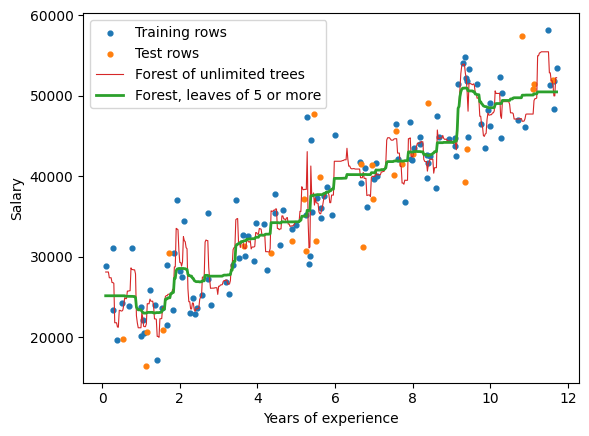

In [ ]:
plt.scatter(X_train, y_train, color="tab:blue", s=12, label="Training rows")
plt.scatter(X_test, y_test, color="tab:orange", s=12, label="Test rows")
plt.plot(grid, models["random forest"].predict(grid), color="tab:red", linewidth=0.8, label="Forest of unlimited trees")
plt.plot(grid, models["random forest, leaves of 5 or more"].predict(grid), color="tab:green", linewidth=2, label="Forest, leaves of 5 or more")
plt.xlabel("Years of experience")
plt.ylabel("Salary")
plt.legend()
plt.show()

The forest of unlimited trees (red) still jumps towards individual training rows; the forest of limited trees (green) is a smooth staircase that follows the trend.

## Which features matter

A forest can report how much each feature contributed. On [California housing](../../basic-workflows/california_by_hand.ipynb), with eight features:

In [ ]:
from sklearn.datasets import fetch_california_housing

housing = fetch_california_housing(as_frame=True).frame
X_housing = housing.drop(columns="MedHouseVal")
y_housing = housing["MedHouseVal"]
X_housing_train, X_housing_test, y_housing_train, y_housing_test = train_test_split(
    X_housing, y_housing, test_size=0.2, random_state=42)

housing_forest = RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1).fit(X_housing_train, y_housing_train)

`feature_importances_` measures, for each feature, how much the splits on it reduced the error inside the trees, averaged over the trees and scaled to add up to 1. **Permutation importance** measures something more direct: how much the error on the *test* rows grows when one feature's values are shuffled, which breaks its relation with the target while keeping everything else:

In [ ]:
from sklearn.inspection import permutation_importance

permutation = permutation_importance(housing_forest, X_housing_test, y_housing_test, n_repeats=5, random_state=42, n_jobs=-1)
pd.DataFrame({
    "impurity importance": housing_forest.feature_importances_,
    "permutation importance": permutation.importances_mean,
}, index=X_housing.columns).sort_values("permutation importance", ascending=False).round(3)

,impurity importance,permutation importance
MedInc,0.525,0.731
Latitude,0.089,0.440
Longitude,0.088,0.335
AveOccup,0.138,0.202
HouseAge,0.055,0.070
AveRooms,0.044,0.029
AveBedrms,0.030,0.009
Population,0.031,0.008


Both put income first, but they disagree on the rest. Impurity importance ranks `AveOccup` second and latitude and longitude low; permutation importance gives latitude and longitude much more weight, as the coefficients of [California housing, step by step](../../basic-workflows/california_by_hand.ipynb) suggested. The two measure different things, and impurity importance has two known weaknesses: it is computed on the training rows, so it includes what a tree learned from their noise, and it favours features with many distinct values, which offer more possible splits. Permutation importance on held-out data is the safer reading. Both have a limit in common: shuffling a feature that another one duplicates barely hurts the model, however much the two matter together. And neither says what *causes* a high price: they describe what the model uses.

## How many trees

The number of trees, `n_estimators`, is the forest's least delicate setting. Its effect is measured on the same California data, whose 4,128 test districts give a steady estimate (the 28 test employees of the salaries would mostly show noise):

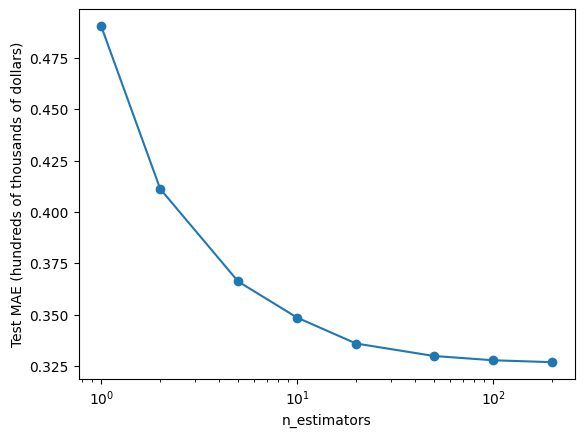

In [ ]:
tree_counts = [1, 2, 5, 10, 20, 50, 100, 200]
errors_by_count = pd.Series({
    count: mean_absolute_error(
        y_housing_test,
        RandomForestRegressor(n_estimators=count, random_state=42, n_jobs=-1).fit(X_housing_train, y_housing_train).predict(X_housing_test))
    for count in tree_counts
}).rename_axis("n_estimators")
errors_by_count.plot(marker="o", logx=True)
plt.ylabel("Test MAE (hundreds of thousands of dollars)")
plt.show()

One tree misses by about \$49,000; ten trees by about \$35,000; a hundred by about \$32,800, and two hundred by almost the same. Each new tree brings less than the one before, and adding trees doesn't make the test error climb, beyond small random wiggles: the cost of more trees is time and memory, not overfitting. That is why `n_estimators` is set as high as the computer comfortably allows, rather than tuned.

## Settings

| Setting | Meaning | Default in scikit-learn | Effect |
| --- | --- | --- | --- |
| `n_estimators` | Number of trees | 100 | More is never much worse, only slower; the gain flattens out |
| `max_features` | Features each split may choose among | all for regression, √(number of features) for classification | Fewer make the trees more different from one another, and each tree weaker |
| `max_depth`, `min_samples_leaf` | Limits on each tree | none: trees grow until their leaves are pure | Smoother predictions; useful with noisy data |
| `n_jobs` | Processor cores used | 1 | `-1` uses all of them: trees are trained independently |
| `random_state` | Seed of the bootstraps and the feature subsets | none | Fixes the result, to reproduce it |

The inventors of random forests, Leo Breiman and Adele Cutler, recommended a third of the features for regression (the default of their software, which R's `randomForest` keeps); scikit-learn's default for regression is all of them, which makes its regression forest plain bagging unless `max_features` is set.

## Strengths and limits

- **Strong with almost no tuning:** the defaults usually give a good model, and more trees don't make it overfit.
- **Little preparation:** like trees, no scaling is needed; scikit-learn's forests accept missing values since version 1.4, but categories must still be encoded as numbers.
- **Parallel:** each tree is trained on its own, so all cores can be used.
- **Harder to read than one tree:** hundreds of trees can't be drawn or followed; importances summarise them, with the caveats above.
- **Larger and slower to predict:** every tree is stored and consulted.
- **No extrapolation:** like any tree, a forest predicts averages of training values, so it can't predict beyond the range of the targets it saw. A salary for 30 years of experience would be the forest's prediction for 11.7 years, the most it ever saw.

Forests average independent trees. [Gradient boosting](gradient_boosting.ipynb) builds trees one after another, each correcting the errors of the ones before; the deep dive [Ensembles beyond trees](deep-dives/ensembles_beyond_trees.ipynb) combines models of any kind.

## Classification *(deep dive)*

For classification, each tree gives a probability for each class, and the forest predicts the class with the highest average probability. A tree without limits has pure leaves, so it gives probability 1 to a single class: its probability is a vote, and the forest's prediction is the most voted class. The difference from a single tree is easiest to see in two dimensions: two interleaved half-moons of points, with enough noise that the classes overlap. The **decision boundary** separates the regions where each model predicts each class:

In [ ]:
from sklearn.datasets import make_moons
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier

X_moons, y_moons = make_moons(n_samples=500, noise=0.3, random_state=42)
X_moons_train, X_moons_test, y_moons_train, y_moons_test = train_test_split(X_moons, y_moons, test_size=0.3, random_state=42)

tree_classifier = DecisionTreeClassifier(random_state=42).fit(X_moons_train, y_moons_train)
forest_classifier = RandomForestClassifier(n_estimators=200, random_state=42).fit(X_moons_train, y_moons_train)
{"tree": tree_classifier.score(X_moons_test, y_moons_test), "forest": forest_classifier.score(X_moons_test, y_moons_test)}

{'tree': 0.8533333333333334, 'forest': 0.9}

`score` is the share of test points classified correctly (the *accuracy*; [Evaluating a classifier](../../evaluation/classification_metrics.ipynb) explains it and its limits). The boundaries:

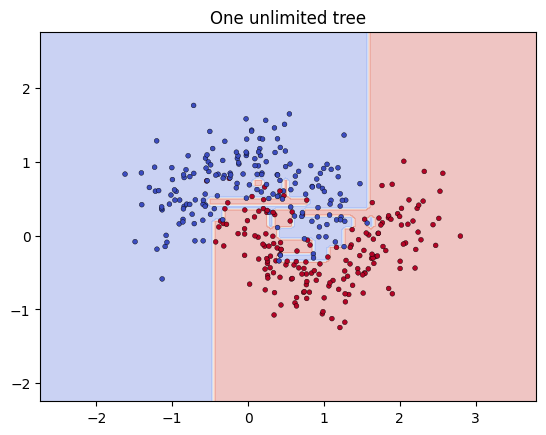

In [ ]:
from sklearn.inspection import DecisionBoundaryDisplay


def plot_boundary(classifier, title):
    DecisionBoundaryDisplay.from_estimator(classifier, X_moons, response_method="predict", alpha=0.3, cmap="coolwarm")
    plt.scatter(X_moons_train[:, 0], X_moons_train[:, 1], c=y_moons_train, s=12, cmap="coolwarm", edgecolors="k", linewidths=0.3)
    plt.title(title)
    plt.show()


plot_boundary(tree_classifier, "One unlimited tree")

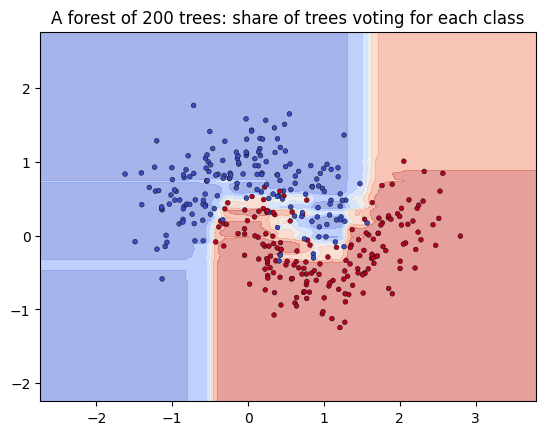

In [ ]:
DecisionBoundaryDisplay.from_estimator(forest_classifier, X_moons, response_method="predict_proba", alpha=0.5, cmap="coolwarm")
plt.scatter(X_moons_train[:, 0], X_moons_train[:, 1], c=y_moons_train, s=12, cmap="coolwarm", edgecolors="k", linewidths=0.3)
plt.title("A forest of 200 trees: share of trees voting for each class")
plt.show()

The single tree draws hard borders and is completely sure everywhere: each of its leaves holds training points of a single class, so it predicts that class with no hesitation, including in thin strips cut around single points of the other class. The forest's colours are the share of its trees that vote for each class: deep where they agree, pale where they split, which is exactly where the two moons overlap. Its predictions are the stronger colour at each point, and its test accuracy is higher: 0.90 against 0.85.

## Further material

- [scikit-learn user guide: forests of randomized trees](https://scikit-learn.org/stable/modules/ensemble.html#forest)
- [StatQuest: Random Forests, part 1](https://www.youtube.com/watch?v=J4Wdy0Wc_xQ)
- Breiman, L. (2001). Random forests. *Machine Learning*, 45(1), 5–32.